# Alphabet

Run top to bottom. Inputs are in `../data`; figures are displayed inline.
Input checksums can be verified with `python scripts/render_figures.py --all`.

## Style and layout helpers

In [2]:
from io import BytesIO
from IPython.display import display, Image as InlineImage
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

ROOT = Path('..').resolve()  # Run from notebooks.
DATA = ROOT / 'data'

# Physical paper dimensions, in inches; typography is specified at this size.
PAPER_STYLE = {'font': 'Lato', 'font_size': 7.0, 'tick_size': 6.5,
               'legend_size': 6.3, 'panel_size': 10.0, 'dpi': 450,
               'line_width': 1.05, 'marker_size': 2.8}

def paper_rc():
    mpl.rcParams.update({
        'font.family': PAPER_STYLE['font'], 'font.size': PAPER_STYLE['font_size'],
        'font.weight': 'normal', 'axes.labelweight': 'normal',
        'axes.labelsize': PAPER_STYLE['font_size'], 'axes.labelpad': 2.5,
        'xtick.labelsize': PAPER_STYLE['tick_size'],
        'ytick.labelsize': PAPER_STYLE['tick_size'],
        'legend.fontsize': PAPER_STYLE['legend_size'], 'legend.frameon': False,
        'legend.handlelength': 1.5, 'legend.labelspacing': .35,
        'axes.spines.top': False, 'axes.spines.right': False,
        'axes.linewidth': .65, 'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
        'xtick.major.width': .6, 'ytick.major.width': .6,
        'xtick.major.pad': 2, 'ytick.major.pad': 2,
        'grid.linewidth': .45, 'grid.color': '#dedde1',
        'mathtext.fontset': 'custom', 'mathtext.rm': 'Lato',
        'mathtext.it': 'Lato:italic', 'mathtext.bf': 'Lato:bold',
        'mathtext.cal': 'Lato', 'mathtext.sf': 'Lato', 'mathtext.tt': 'Lato',
        'path.simplify': False, 'savefig.bbox': None,
    })

def paper_axis(axis):
    axis.xaxis.label.set_size(PAPER_STYLE['font_size'])
    axis.yaxis.label.set_size(PAPER_STYLE['font_size'])
    axis.tick_params(labelsize=PAPER_STYLE['tick_size'], width=.6, length=2.5)
    for spine in axis.spines.values():
        spine.set_linewidth(.65)

def paper_letter(figure, axis, letter, *, dx=-.20, dy=.07):
    # Offsets are physical inches, independent of the subplot aspect ratio.
    bounds = axis.get_position(original=True)
    width, height = figure.get_size_inches()
    return figure.text(bounds.x0 + dx/width, bounds.y1 + dy/height, letter,
                       ha='left', va='bottom', fontsize=PAPER_STYLE['panel_size'],
                       fontweight='bold')

def physical_axes(figure, rectangle):
    width, height = figure.get_size_inches()
    x, y, w, h = rectangle
    return figure.add_axes([x/width, y/height, w/width, h/height])

## Aligned-residue identity (B)

In [3]:
def make_alignment_identity_figure(
    axis, data_path: Path, maximum_per_superfamily: int | None = None
):
    """AA and TEA identity inside shared-family SCOP domain spans."""
    frame = pd.read_parquet(data_path).dropna(subset=["cv_tea_identity"]).copy()
    if maximum_per_superfamily is not None:
        shared_superfamilies = frame.shared_families.map(
            lambda value: sorted({
                family.rsplit(".", 1)[0] for family in value.split(";")
            })
        )
        frame = frame.loc[shared_superfamilies.map(len).eq(1)].copy()
        frame["_shared_superfamily"] = shared_superfamilies.loc[frame.index].str[0]
        within_superfamily = frame.groupby(
            "_shared_superfamily", sort=False
        ).cumcount()
        frame = frame.loc[within_superfamily.lt(maximum_per_superfamily)]

    data = {
        "Amino acid": 100 * frame.aa_identity.dropna().to_numpy(),
        "TEA CV": 100 * frame.cv_tea_identity.dropna().to_numpy(),
        "TEA": 100 * frame.tea_identity.dropna().to_numpy(),
    }
    positions = np.arange(1, len(data) + 1)
    fill_colors = ['#a9cde3', '#d2d0d4', '#9274ad']
    marker_colors = ['#3E88B7', '#77747b', '#654183']
    violin_parts = axis.violinplot(
        list(data.values()), positions=positions, showextrema=False
    )
    for body, color in zip(violin_parts["bodies"], fill_colors):
        body.set_facecolor(color)
        body.set_edgecolor("none")
        body.set_alpha(1)
    for position, values, color in zip(positions, data.values(), marker_colors):
        q1, q3 = np.percentile(values, [25, 75])
        axis.vlines(
            position, q1, q3, color="black", linewidth=.9,
            label="IQR" if position == 1 else None, zorder=3,
        )
        axis.scatter(
            [position, position], [q1, q3], color="black", marker="_", s=17, linewidths=.55,
            zorder=4,
        )
        axis.scatter(
            position, np.mean(values), color=color, edgecolor="black", s=17, linewidths=.55,
            marker="o", label="Mean" if position == 1 else None, zorder=5,
        )
        axis.scatter(
            position, np.median(values), color=color, edgecolor="black", s=17, linewidths=.55,
            marker="D", label="Median" if position == 1 else None, zorder=5,
        )
    axis.set(
        xticks=positions, xticklabels=list(data),
        ylabel="Sequence identity (%)",
    )
    axis.set_xticklabels(list(data), fontsize=6.5, fontweight='normal')
    axis.legend(loc='upper left', frameon=False, fontsize=6., handlelength=1.2, labelspacing=.25)

## Alphabet sensitivity and precision–recall (E–F)

In [4]:
METHOD_LABELS = {
    "aa": "AA",
    "structural_3di": "Structural 3Di",
    "prostt5_3di": "ProstT5 3Di (domain)",
    "prostt5_3di_full_chain": "ProstT5 3Di",
    "tea_full": "TEA",
}

def cv_band(frame, metric):
    folds = []
    for method, fold in frame.loc[frame["method"].str.startswith("tea_cv_outer")].groupby("method"):
        fold = fold.sort_values("point_index")
        x = fold["x"].to_numpy(float)
        y = fold["y"].to_numpy(float)
        # The shared grid runs from low to high recall.
        if metric in {"pr", "weighted_pr"}:
            x = x[::-1]
            y = y[::-1]
        folds.append((x, y))
    if not folds:
        return None
    left = max(x[0] for x, _ in folds)
    right = min(x[-1] for x, _ in folds)
    grid = np.unique(np.concatenate([x for x, _ in folds]))
    grid = grid[(grid >= left) & (grid <= right)]
    values = []
    for x, y in folds:
        if metric in {"pr", "weighted_pr"}:
            index = np.searchsorted(x, grid, side="left")
        else:
            index = np.searchsorted(x, grid, side="right") - 1
        values.append(y[index])
    values = np.asarray(values)
    mean = values.mean(axis=0)
    half = 1.96 * values.std(axis=0, ddof=0) / np.sqrt(values.shape[0])
    step = "pre" if metric in {"pr", "weighted_pr"} else "post"
    return grid, mean, np.clip(mean - half, 0, 1), np.clip(mean + half, 0, 1), step

def draw_alphabet_curves(axis, family_curves, metric):
    frame = family_curves.loc[family_curves.metric.eq(metric)]
    x, mean, lower, upper, step = cv_band(frame, metric)
    axis.fill_between(x, lower, upper, step=step, color='#929097', alpha=.20)
    axis.step(x, mean, where=step, color='#929097', linewidth=1.10, label='TEA CV')
    for method, rows in frame.groupby('method', sort=False):
        if method.startswith('tea_cv_outer'):
            continue
        label = METHOD_LABELS[method]
        color, marker, dash = CURVE_STYLE[label]
        rows = rows.sort_values('point_index')
        markers = np.unique(np.linspace(0, len(rows) - 1, min(11, len(rows)), dtype=int))
        axis.step(rows.x, rows.y, where='post', label=label, color=color,
                  marker=marker, linestyle=dash, linewidth=1.10, markersize=2.1,
                  markevery=markers.tolist())

    if metric == 'sensitivity':
        axis.set(xlim=(-.025, 1.025), ylim=(-.025, 1.025),
                 xlabel='Fraction of queries', ylabel='1st-FP sensitivity')
    else:
        axis.set(xlim=(0, 1), ylim=(0, 1), xlabel='Recall', ylabel='Weighted precision')
    axis.grid(axis='y', linestyle='--', alpha=.20)
    add_domain_alphabet_curve(axis, metric, 'family')
    for line in axis.lines:
        line.get_path().should_simplify = False


def add_domain_alphabet_curve(axis, metric, hierarchy):
    if metric == 'sensitivity':
        path = DATA/'plot_tables/scop/alphabet/domain_only/metrics.json'
        payload = json.loads(path.read_text())
        values = np.asarray([row['sensitivity'] for row in
                             payload['levels'][hierarchy]['per_query'].values()
                             if row.get('sensitivity') is not None],dtype=float)
        values = np.sort(values[np.isfinite(values)])[::-1]
        x = np.arange(values.size+1,dtype=float)/max(values.size,1)
        y = np.r_[values,0.0]
    else:
        raw_root = ROOT/'data/plot_tables/scop/alphabet/raw_score'
        frame = pd.read_csv(raw_root/f'tea_domain_{hierarchy}_curve.tsv',sep='\t')
        x = frame.recall.to_numpy(float)
        y = frame.weighted_precision.to_numpy(float)
    line = axis.step(x,y,where='post',label='TEA(domain)',color='#9672b2',
                     linestyle=(0,(4,1.7)),linewidth=1.10,marker='D',
                     markersize=1.9,markevery=np.unique(np.linspace(0,len(x)-1,11,dtype=int)),
                     zorder=4)[0]
    line.get_path().should_simplify = False
    return line


# Figure 1 shows family retrieval with raw-score ranking.


CURVE_STYLE = {
    'AA': ('#3E88B7', 'P', (0, (5, 2.5))),
    'Structural 3Di': ('#d84b48', 'X', (0, (3.2, 1.5, 1., 1.5))),
    'ProstT5 3Di': ('#df951e', '^', '-'),
    'ProstT5 3Di (domain)': ('#c68d45', 'v', (0, (2.3, 1.4))),
    'TEA': ('#654183', 'o', '-'),
}

## Sankeys (C–D)

In [5]:
from matplotlib.patches import PathPatch
from matplotlib.transforms import Affine2D
from sankeyflow import Sankey

SANKEY_DATA=ROOT/'data/plot_tables/model/alphabet_transition'

tea_sse=pd.read_csv(SANKEY_DATA/'tea_to_dssp_counts_scop_plus_high_plddt.csv',index_col=0)
sse_3di=pd.read_csv(SANKEY_DATA/'dssp_to_i3d_counts_scop_plus_high_plddt.csv',index_col=0)
tea_plddt=pd.read_csv(SANKEY_DATA/'tea_to_plddt_counts.csv',index_col=0)
plddt_3di=pd.read_csv(SANKEY_DATA/'plddt_to_i3d_counts.csv',index_col=0)
names=['Helix','Sheet','Coil']
groups=['HGI','EB','TSC']
ss_colors=['#2C78AD','#4D9A73','#90979E']
left_sse=np.column_stack([tea_sse[list(group)].sum(1) for group in groups])
right_sse=np.row_stack([sse_3di.loc[list(group)].sum(0) for group in groups])
np.testing.assert_array_equal(left_sse.sum(0),right_sse.sum(1))

def draw_sankey(ax,left_letters,middle_names,right_letters,left,right,colors,three_state=False):
    left=np.asarray(left,dtype=np.int64);right=np.asarray(right,dtype=np.int64)
    np.testing.assert_array_equal(left.sum(0),right.sum(1))
    if three_state:
        lf=left/left.sum(1,keepdims=True);rf=right.T/right.sum(0)[:,None]
        lo=sorted(range(20),key=lambda i:(lf[i].argmax(),-lf[i].max()))
        ro=sorted(range(20),key=lambda i:(rf[i].argmax(),-rf[i].max()))
    else:
        lo=np.argsort((left@np.arange(left.shape[1]))/left.sum(1),kind='stable')
        ro=np.argsort((np.arange(right.shape[0])@right)/right.sum(0),kind='stable')
    nodes=[[(f't:{left_letters[i]}',int(left[i].sum()),{'label':left_letters[i],'label_pos':'left','color':'#c9c5cc'}) for i in lo],
           [(f'm:{j}',int(left[:,j].sum()),{'label':label,'label_pos':'center','color':color}) for j,(label,color) in enumerate(zip(middle_names,colors))],
           [(f'd:{right_letters[k]}',int(right[:,k].sum()),{'label':right_letters[k].lower(),'label_pos':'right','color':'#c9c5cc'}) for k in ro]]
    flows=[]
    for i in lo:
        for j,color in enumerate(colors):
            if left[i,j]:flows.append((f't:{left_letters[i]}',f'm:{j}',int(left[i,j]),{'color':mpl.colors.to_rgba(color,.42)}))
    for j,color in enumerate(colors):
        for k in ro:
            if right[j,k]:flows.append((f'm:{j}',f'd:{right_letters[k]}',int(right[j,k]),{'color':mpl.colors.to_rgba(color,.42)}))
    sankey=Sankey(flows=flows,nodes=nodes,flow_color_mode='',node_width=.025,node_pad_y_min=0,node_pad_y_max=0,
        node_opts={'label_format':'{label}','label_pad_x':.012,'label_opts':{'fontsize':5.4}})
    sankey.draw(ax=ax)
    max_x=max(node.x+node.width for level in sankey.nodes for node in level)
    transform=Affine2D.from_values(0,-1,-1,0,1,max_x)
    for element in [*sankey.flows,*(node for level in sankey.nodes for node in level)]:
        artist=element.artist
        path=artist.get_path().transformed(artist.get_patch_transform())
        replacement=PathPatch(transform.transform_path(path),facecolor=artist.get_facecolor(),
            edgecolor=artist.get_edgecolor(),linewidth=artist.get_linewidth(),alpha=artist.get_alpha(),zorder=artist.get_zorder())
        artist.remove();ax.add_patch(replacement);element.artist=replacement
    # Draw separators at the boundaries between abundance-scaled segments.
    for index in (0,2):
        level=sankey.nodes[index]
        bounds=[node.artist.get_path().get_extents() for node in level]
        for box in bounds:
            for x in (box.x0,box.x1):
                ax.plot([x,x],[box.y0,box.y1],color='white',linewidth=.65,zorder=5)
                edge=box.y0 if index==0 else box.y1
                direction=-1 if index==0 else 1
                ax.plot([x,x],[edge,edge+direction*.035],color='#817b87',linewidth=.35,zorder=5)
    for index,level in enumerate(sankey.nodes):
        for node in level:
            text=node.text
            if text is None:continue
            text.set_position(transform.transform(text.get_position()))
            text.set_ha('center');text.set_va('bottom' if index==0 else 'top' if index==2 else 'center')
            text.set_fontsize(5.4 if index!=1 else 6.1)
            if index==0:text.set_fontstyle('italic')
            if index==1:text.set_bbox(dict(facecolor='white',edgecolor='none',alpha=.92,pad=1.3))
    ax.set(xlim=(-.035,1.025),ylim=(-.07,max_x+.07),aspect='auto')
    ax.axis('off')
    fig.canvas.draw();renderer=fig.canvas.get_renderer()
    for index,direction in [(0,1),(2,-1)]:
        ends=[]
        for text in sorted([n.text for n in sankey.nodes[index] if n.text is not None],key=lambda t:t.get_window_extent(renderer).x0):
            box=text.get_window_extent(renderer)
            lane=next((i for i,end in enumerate(ends) if box.x0>end+1.5),len(ends))
            if lane==len(ends):ends.append(box.x1)
            else:ends[lane]=box.x1
            if lane:
                x,y=ax.transData.transform(text.get_position())
                text.set_position(ax.transData.inverted().transform((x,y+direction*lane*6*fig.dpi/72)))
    for label,level in zip(['TEA','DSSP' if three_state else 'pLDDT','3Di'],sankey.nodes):
        y=np.mean([max_x-(n.x+n.width/2) for n in level])
        ax.text(-.040,y,label,ha='right',va='center',fontsize=6.0,weight='bold')

## Draw the figure

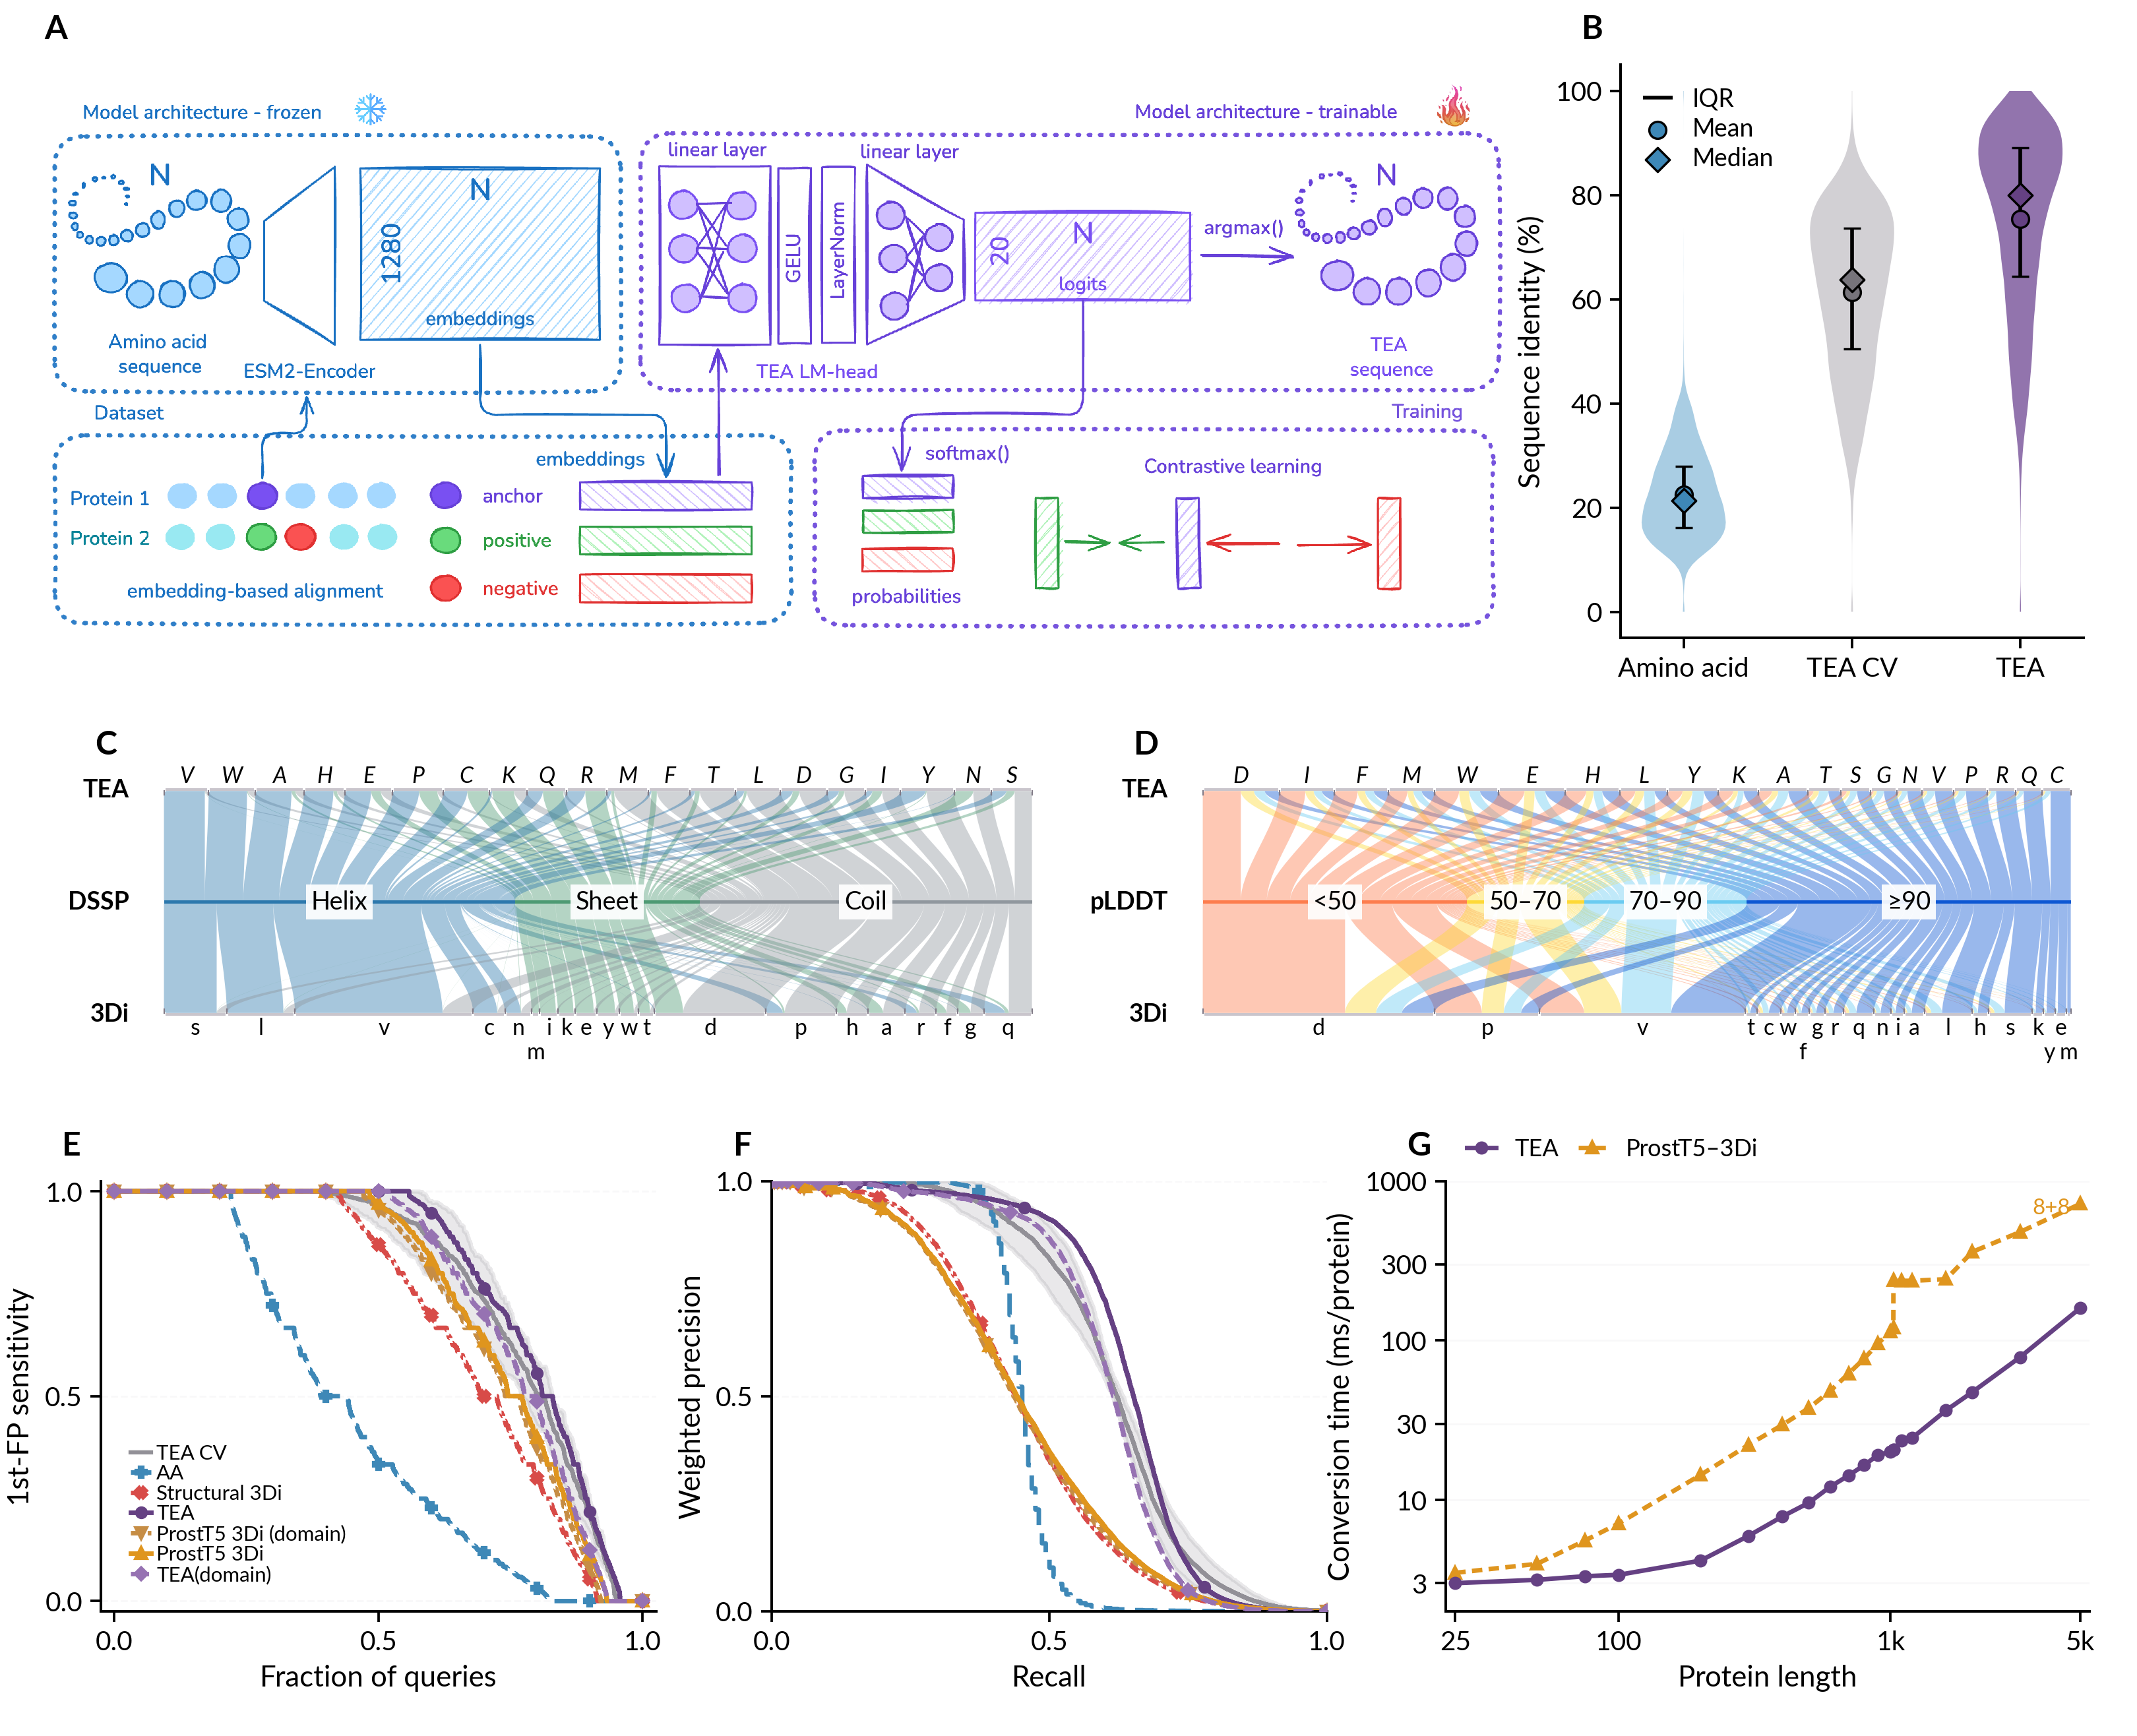

In [6]:
# All rectangles are (left, bottom, width, height) in paper inches.
# The top is approximately 3:1; the lower rows have independent widths/heights.
LAYOUT = {'size': (7.2, 5.85),
    'A': (.15, 3.70, 4.93, 1.93), 'B': (5.46, 3.70, 1.56, 1.93),
    'C': (.45, 2.40, 3.10, .82), 'D': (3.95, 2.40, 3.10, .82),
    'E': [(.34, .42, 1.87, 1.45), (2.60, .42, 1.87, 1.45)],
    'G': (4.87, .42, 2.17, 1.45)}
paper_rc()
fig = plt.figure(figsize=LAYOUT['size'], dpi=150)
A,B,C,D = [physical_axes(fig, LAYOUT[name]) for name in 'ABCD']
E = [physical_axes(fig, rect) for rect in LAYOUT['E']]
G = physical_axes(fig, LAYOUT['G'])

R = ROOT/'data/plot_tables/model'
architecture = plt.imread(ROOT/'data/assets/architecture.png')
A.imshow(architecture,interpolation='nearest',aspect='equal')
A.set_axis_off()
make_alignment_identity_figure(B, R/'alignment_identity/identities.parquet',
                               maximum_per_superfamily=100)

draw_sankey(C,tea_sse.index.to_list(),names,sse_3di.columns.to_list(),
    left_sse,right_sse,ss_colors,True)
draw_sankey(D,tea_plddt.index.to_list(),['<50','50–70','70–90','≥90'],plddt_3di.columns.to_list(),
    tea_plddt.to_numpy(),plddt_3di.to_numpy(),['#fd7d4d','#fed936','#6acbf1','#0d57d3'])

curves = pd.read_csv(DATA/'plot_tables/scop/alphabet/raw_score/curves.tsv', sep='\t')
family_curves = curves.loc[curves.hierarchy.eq('family')]
draw_alphabet_curves(E[0], family_curves, 'sensitivity')
draw_alphabet_curves(E[1], family_curves, 'weighted_pr')
E[0].lines[0].set_linewidth(1.0)
E[1].lines[0].set_linewidth(1.0)
E[0].legend(loc='lower left', bbox_to_anchor=(.02,.02), frameon=False, fontsize=5.0,
            ncol=1, handlelength=1.0, handletextpad=.25, labelspacing=.08)
for axis in E:
    axis.set_xticks([0,.5,1])
    axis.set_yticks([0,.5,1])

# Matched A100 timings. At length 5000, ProstT5 used two batches of eight.
timing_root = ROOT/'data/plot_tables/timing/production_budget'
timing = pd.read_csv(timing_root/'conversion_batch16_plotted.tsv',sep='\t')
rotary_timing = pd.read_csv(timing_root/'tea_rotary_batch16.tsv',sep='\t')
points = rotary_timing.loc[rotary_timing.method.eq('fp16_rope32')].sort_values('protein_length')
G.plot(points.protein_length,points.median_milliseconds_per_protein,
       color='#654183',linestyle='-',linewidth=1.10,marker='o',markersize=2.2,
       label='TEA',zorder=4)
points = timing.loc[timing.method.eq('ProstT5-3Di') & timing.protein_length.le(5000)].sort_values('protein_length')
G.plot(points.protein_length,points.median_milliseconds_per_protein,
       color='#df951e',linestyle=(0,(2.3,1.4)),linewidth=1.10,marker='^',markersize=2.2,
       label='ProstT5–3Di',zorder=3)
G.set(xscale='log',yscale='log',xlim=(23,5400),ylim=(2,1000),
      xlabel='Protein length',ylabel='Conversion time (ms/protein)')
G.set_xticks([25,100,1000,5000],['25','100','1k','5k'])
G.set_yticks([3,10,30,100,300,1000],['3','10','30','100','300','1000'])
G.minorticks_off()
G.grid(axis='y',alpha=.20)
G.legend(loc='upper left',bbox_to_anchor=(.0,1.15),ncol=2,fontsize=5.8,
         frameon=False,handlelength=1.2,columnspacing=.8)
G.text(.97,.96,'8+8',transform=G.transAxes,ha='right',va='top',
       fontsize=5.3,color='#df951e')
for axis in (B,*E,G):
    paper_axis(axis)
for axis, letter in [(A,'A'),(B,'B'),(C,'C'),(D,'D'),(E[0],'E'),(E[1],'F'),(G,'G')]:
    label = paper_letter(fig, axis, letter, dx=-.13 if axis is not A else 0)
    label.set_fontsize(8.0)
with BytesIO() as image_buffer:
    fig.savefig(image_buffer, format='png', dpi=PAPER_STYLE['dpi'], facecolor='white')
    plt.close(fig)
    display(InlineImage(data=image_buffer.getvalue()))